# Walmart — EDA i jakość danych

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

%matplotlib inline
%load_ext autoreload
%autoreload 2

from src.config import CAT, INK, DIVERGING, FEATURE_COLS, TARGET, setup_style
from src.data import load_raw, clean, time_split
setup_style()

## 1. Wczytanie danych

In [2]:
df_raw = load_raw()
print(f"Liczba wierszy: {df_raw.shape[0]:,}".replace(',', ' '))
print(f"Liczba kolumn: {df_raw.shape[1]}")
df_raw.head()

Liczba wierszy: 421 570
Liczba kolumn: 16


,Store,Date,IsHoliday,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,2010-02-05,0,1.0,24924.50,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315
1,1,2010-02-05,0,26.0,11737.12,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315
2,1,2010-02-05,0,17.0,13223.76,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315
3,1,2010-02-05,0,45.0,37.44,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315
4,1,2010-02-05,0,28.0,1085.29,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315


In [3]:
df_raw.dtypes.to_frame('dtype')

,dtype
Store,int64
Date,object
IsHoliday,int64
Dept,float64
Weekly_Sales,float64
Temperature,float64
Fuel_Price,float64
MarkDown1,float64
MarkDown2,float64
MarkDown3,float64


## 2. Jakość danych

In [4]:
quality = pd.DataFrame({
    'braki (NaN)': df_raw.isna().sum(),
    '% braków': (df_raw.isna().mean()*100).round(2),
    'unikalne wartości': df_raw.nunique(),
})
print("Duplikaty wierszy:", df_raw.duplicated().sum())
quality

Duplikaty wierszy: 0


,braki (NaN),% braków,unikalne wartości
Store,0,0.0,45
Date,0,0.0,143
IsHoliday,0,0.0,2
Dept,0,0.0,81
Weekly_Sales,0,0.0,359464
Temperature,0,0.0,3528
Fuel_Price,0,0.0,892
MarkDown1,0,0.0,2278
MarkDown2,0,0.0,1499
MarkDown3,0,0.0,1662


In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Store,421570.0,22.200546,12.785297,1.000,11.000000,22.00000,33.000000,45.000000
IsHoliday,421570.0,0.070358,0.255750,0.000,0.000000,0.00000,0.000000,1.000000
Dept,421570.0,44.260317,30.492054,1.000,18.000000,37.00000,74.000000,99.000000
Weekly_Sales,421570.0,15981.258123,22711.183519,-4988.940,2079.650000,7612.03000,20205.852500,693099.360000
Temperature,421570.0,60.090059,18.447931,-2.060,46.680000,62.09000,74.280000,100.140000
Fuel_Price,421570.0,3.361027,0.458515,2.472,2.933000,3.45200,3.738000,4.468000
MarkDown1,421570.0,2590.074819,6052.385934,0.000,0.000000,0.00000,2809.050000,88646.760000
MarkDown2,421570.0,879.974298,5084.538801,-265.760,0.000000,0.00000,2.200000,104519.540000
MarkDown3,421570.0,468.087665,5528.873453,-29.100,0.000000,0.00000,4.540000,141630.610000
MarkDown4,421570.0,1083.132268,3894.529945,0.000,0.000000,0.00000,425.290000,67474.850000


In [6]:
print("Liczba sklepów (Store):", df_raw['Store'].nunique())
print("Liczba działów (Dept):", df_raw['Dept'].nunique())
print("Unikalne kombinacje Store-Dept:", df_raw.groupby(['Store','Dept']).ngroups)
print("Zakres dat:", df_raw['Date'].min(), '-', df_raw['Date'].max())
print("Liczba unikalnych tygodni:", df_raw['Date'].nunique())
print("\nRozkład Type:\n", df_raw['Type'].value_counts())
print("\nRozkład IsHoliday:\n", df_raw['IsHoliday'].value_counts())
print("\nWiersze z Weekly_Sales < 0:", (df_raw['Weekly_Sales'] < 0).sum())
print("Wiersze z Weekly_Sales == 0:", (df_raw['Weekly_Sales'] == 0).sum())
for c in ['MarkDown1','MarkDown2','MarkDown3','MarkDown4','MarkDown5']:
    print(f"Ujemne wartości w {c}:", (df_raw[c] < 0).sum())

Liczba sklepów (Store): 45
Liczba działów (Dept): 81
Unikalne kombinacje Store-Dept: 3331
Zakres dat: 2010-02-05 - 2012-10-26
Liczba unikalnych tygodni: 143

Rozkład Type:
 Type
3    215478
2    163495
1     42597
Name: count, dtype: int64

Rozkład IsHoliday:
 IsHoliday
0    391909
1     29661
Name: count, dtype: int64

Wiersze z Weekly_Sales < 0: 1285
Wiersze z Weekly_Sales == 0: 73
Ujemne wartości w MarkDown1: 0
Ujemne wartości w MarkDown2: 1311
Ujemne wartości w MarkDown3: 257
Ujemne wartości w MarkDown4: 0
Ujemne wartości w MarkDown5: 0


**Obserwacje o jakości danych.** Zbiór nie zawiera braków danych ani duplikatów wierszy —
to już wynik wcześniejszego, częściowego przetworzenia (m.in. `Type` jest zakodowany
liczbowo jako 1/2/3, a nie jako oryginalne litery A/B/C, więc w dalszej części traktujemy
go jako zmienną nominalną bez zakładania kolejności). Wymaga jednak dalszego czyszczenia:
kolumna `Date` jest tekstem, 1 285 wierszy (0,30%) ma ujemną `Weekly_Sales`, a `MarkDown2`
i `MarkDown3` zawierają odpowiednio 1 311 i 257 ujemnych wartości. Dane obejmują 143
kolejne tygodnie (2010-02-05 – 2012-10-26), 45 sklepów, 81 działów i 3 331 unikalnych par
sklep–dział, przy czym nie każda para występuje we wszystkich tygodniach.

## 3. Analiza eksploracyjna (EDA)

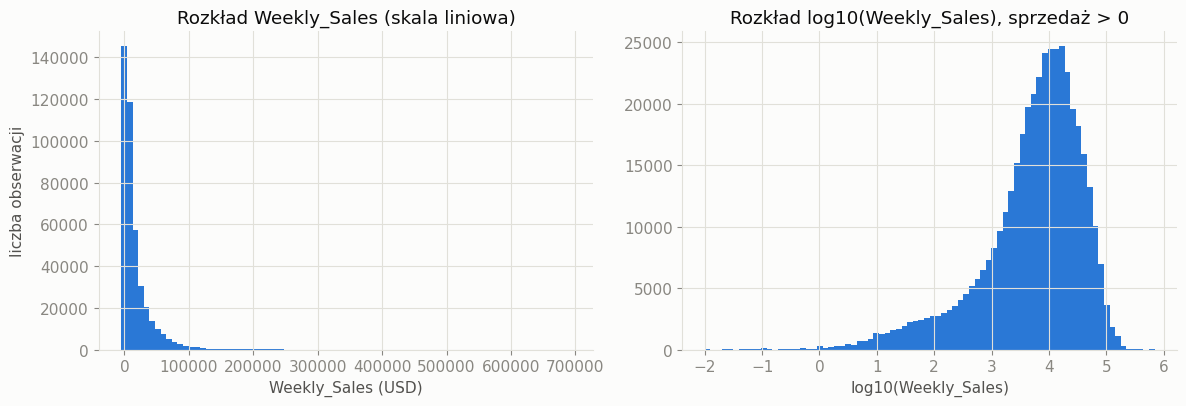

count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(df_raw['Weekly_Sales'], bins=80, color=CAT[0], edgecolor='none')
axes[0].set_title('Rozkład Weekly_Sales (skala liniowa)')
axes[0].set_xlabel('Weekly_Sales (USD)')
axes[0].set_ylabel('liczba obserwacji')

pos = df_raw.loc[df_raw['Weekly_Sales'] > 0, 'Weekly_Sales']
axes[1].hist(np.log10(pos), bins=80, color=CAT[0], edgecolor='none')
axes[1].set_title('Rozkład log10(Weekly_Sales), sprzedaż > 0')
axes[1].set_xlabel('log10(Weekly_Sales)')
plt.tight_layout()
plt.show()

print(df_raw['Weekly_Sales'].describe())

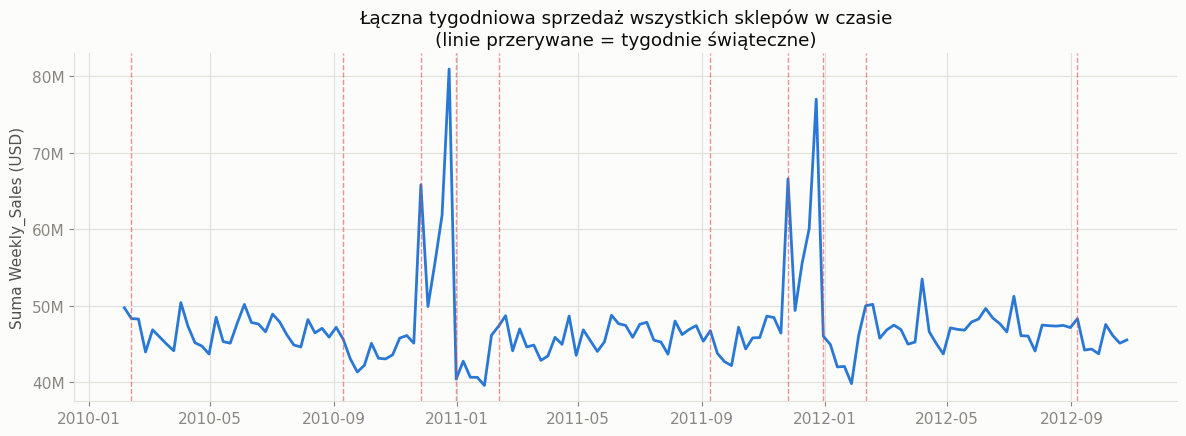

In [8]:
tmp = df_raw.copy()
tmp['Date'] = pd.to_datetime(tmp['Date'])
weekly_total = tmp.groupby('Date')['Weekly_Sales'].sum()
holiday_dates = tmp.loc[tmp['IsHoliday'] == 1, 'Date'].unique()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(weekly_total.index, weekly_total.values, color=CAT[0], linewidth=2)
for hd in holiday_dates:
    ax.axvline(hd, color=CAT[7], linewidth=1, linestyle='--', alpha=0.6)
ax.set_title('Łączna tygodniowa sprzedaż wszystkich sklepów w czasie\n(linie przerywane = tygodnie świąteczne)')
ax.set_ylabel('Suma Weekly_Sales (USD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1e6:.0f}M'))
plt.tight_layout()
plt.show()

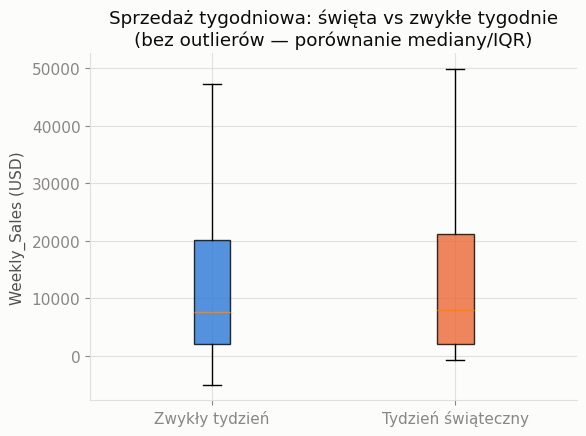

,mean,median,std,count
IsHoliday,,,,
0,15901.445069,7589.95,22330.747450,391909
1,17035.823187,7947.74,27222.000409,29661


In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
data_h = [df_raw.loc[df_raw['IsHoliday'] == 0, 'Weekly_Sales'],
          df_raw.loc[df_raw['IsHoliday'] == 1, 'Weekly_Sales']]
bp = ax.boxplot(data_h, tick_labels=['Zwykły tydzień', 'Tydzień świąteczny'],
                 showfliers=False, patch_artist=True)
for patch, color in zip(bp['boxes'], [CAT[0], CAT[1]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
ax.set_ylabel('Weekly_Sales (USD)')
ax.set_title('Sprzedaż tygodniowa: święta vs zwykłe tygodnie\n(bez outlierów — porównanie mediany/IQR)')
plt.tight_layout()
plt.show()

df_raw.groupby('IsHoliday')['Weekly_Sales'].agg(['mean', 'median', 'std', 'count'])

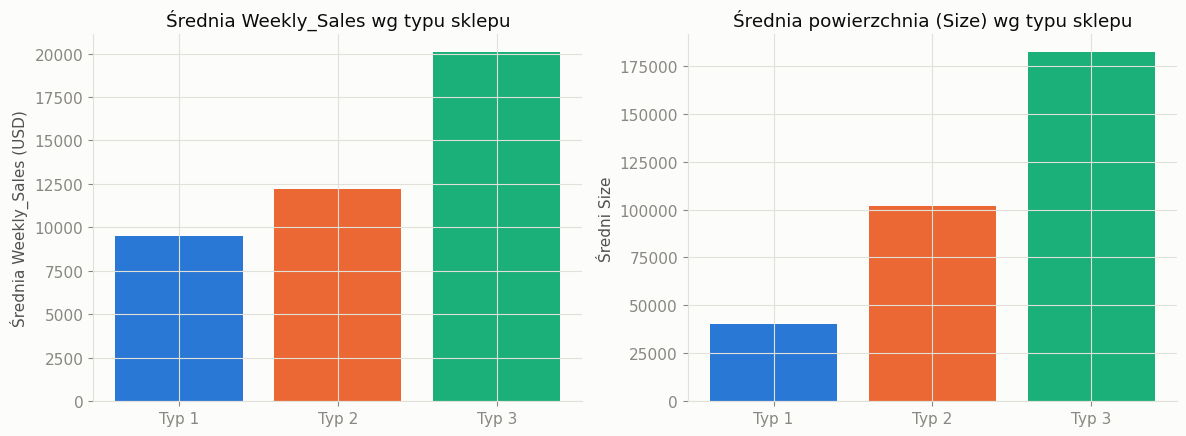

,Weekly_Sales,Size
TypeLabel,,
Typ 1,9519.532538,40535.725286
Typ 2,12237.075977,101818.735827
Typ 3,20099.568043,182231.285486


In [10]:
type_labels = {1: 'Typ 1', 2: 'Typ 2', 3: 'Typ 3'}
tmp2 = df_raw.copy()
tmp2['TypeLabel'] = tmp2['Type'].map(type_labels)
order = ['Typ 1', 'Typ 2', 'Typ 3']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
means = tmp2.groupby('TypeLabel')['Weekly_Sales'].mean().reindex(order)
axes[0].bar(order, means.values, color=CAT[:3])
axes[0].set_title('Średnia Weekly_Sales wg typu sklepu')
axes[0].set_ylabel('Średnia Weekly_Sales (USD)')

sizes = tmp2.groupby('TypeLabel')['Size'].mean().reindex(order)
axes[1].bar(order, sizes.values, color=CAT[:3])
axes[1].set_title('Średnia powierzchnia (Size) wg typu sklepu')
axes[1].set_ylabel('Średni Size')
plt.tight_layout()
plt.show()

tmp2.groupby('TypeLabel')[['Weekly_Sales', 'Size']].mean()

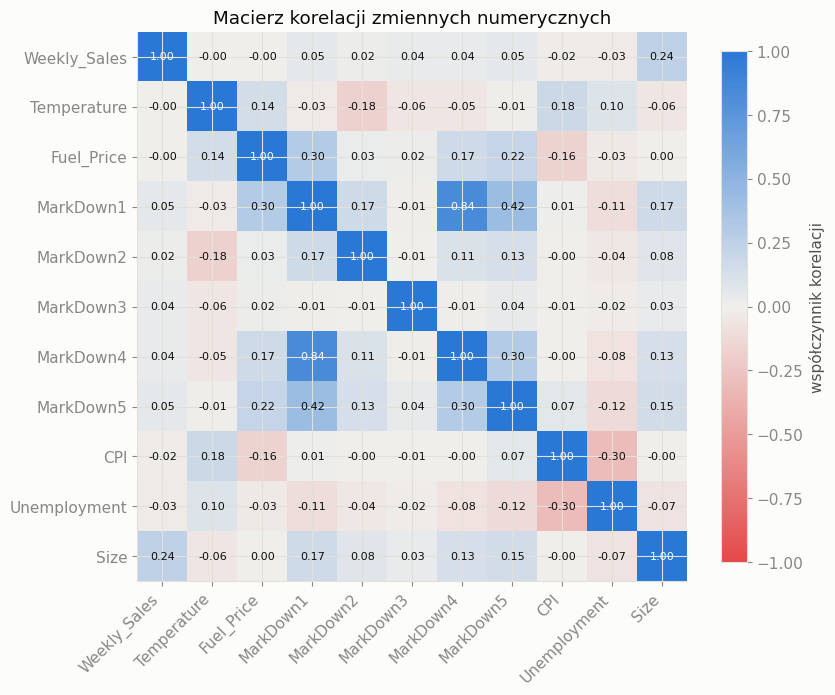

In [11]:
num_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2',
            'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Size']
corr = df_raw[num_cols].corr()

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=45, ha='right')
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        v = corr.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(v) > 0.6 else INK)
ax.set_title('Macierz korelacji zmiennych numerycznych')
fig.colorbar(im, ax=ax, shrink=0.8, label='współczynnik korelacji')
plt.tight_layout()
plt.show()

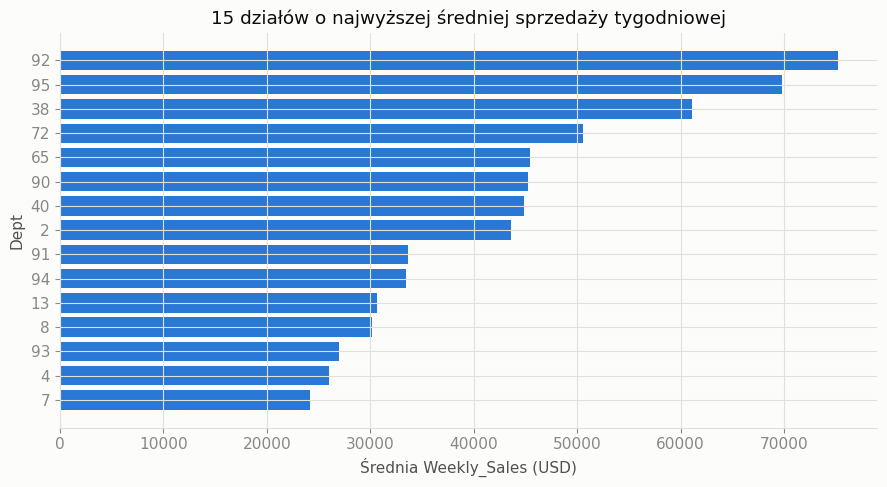

In [12]:
dept_avg = df_raw.groupby('Dept')['Weekly_Sales'].mean().sort_values(ascending=False)
top15 = dept_avg.head(15)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top15.index.astype(int).astype(str)[::-1], top15.values[::-1], color=CAT[0])
ax.set_xlabel('Średnia Weekly_Sales (USD)')
ax.set_ylabel('Dept')
ax.set_title('15 działów o najwyższej średniej sprzedaży tygodniowej')
plt.tight_layout()
plt.show()

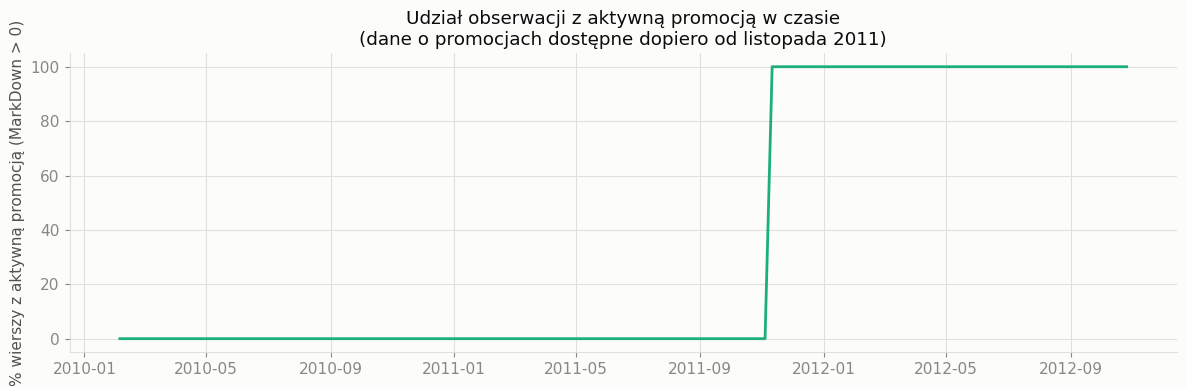

In [13]:
tmp3 = df_raw.copy()
tmp3['Date'] = pd.to_datetime(tmp3['Date'])
md_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
active = tmp3.groupby('Date').apply(lambda d: (d[md_cols].sum(axis=1) > 0).mean())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(active.index, active.values * 100, color=CAT[2], linewidth=2)
ax.set_ylabel('% wierszy z aktywną promocją (MarkDown > 0)')
ax.set_title('Udział obserwacji z aktywną promocją w czasie\n(dane o promocjach dostępne dopiero od listopada 2011)')
plt.tight_layout()
plt.show()

## 3a. Testy statystyczne

Obserwacje z wykresów weryfikujemy formalnie (poziom istotności α = 0,05).

**Normalność rozkładów** — test Shapiro-Wilka (na losowej próbie 5000 obserwacji, bo
dla większych prób test nie jest wiarygodny) oraz test D'Agostino K². H0: rozkład jest normalny.

In [14]:
from src import stats as st

num_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2',
            'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Size']
st.normality_tests(df_raw, num_cols)

,n,skośność,kurtoza,Shapiro W,Shapiro p,D'Agostino K2,D'Agostino p,normalny?
zmienna,,,,,,,,
Weekly_Sales,5000,3.280988,17.408396,0.662472,6.976351e-72,3621.784313,0.000000e+00,False
Temperature,5000,-0.336847,-0.641999,0.979142,1.730869e-26,287.838117,3.138680e-63,False
Fuel_Price,5000,-0.093926,-1.207527,0.949262,1.770578e-38,4571.449973,0.000000e+00,False
MarkDown1,5000,4.655755,33.562138,0.483357,7.375041e-81,4819.131166,0.000000e+00,False
MarkDown2,5000,9.787955,124.969193,0.179504,3.178931e-91,7710.753923,0.000000e+00,False
MarkDown3,5000,13.834598,208.052347,0.062284,2.461051e-94,9188.661134,0.000000e+00,False
MarkDown4,5000,7.731452,78.211902,0.300007,1.360411e-87,6717.803549,0.000000e+00,False
MarkDown5,5000,9.670934,177.755186,0.406821,6.900731e-84,7797.701194,0.000000e+00,False
CPI,5000,0.098880,-1.833158,0.788699,1.244168e-62,19420.431606,0.000000e+00,False


**Różnice między grupami** — ponieważ rozkłady nie są normalne, stosujemy testy
nieparametryczne: Manna-Whitneya (2 grupy: tydzień świąteczny vs zwykły) i
Kruskala-Wallisa (>2 grupy: typ sklepu, dział, sklep). H0: rozkład sprzedaży jest taki sam w grupach.

In [15]:
st.group_tests(df_raw, ['IsHoliday', 'Type', 'Dept', 'Store'])

,test,grupy,statystyka,p,wielkość efektu,istotne?
Weekly_Sales ~ IsHoliday,Mann-Whitney U,2,5.738436e+09,0.000262,0.012692,True
Weekly_Sales ~ Type,Kruskal-Wallis,3,2.287885e+04,0.000000,0.054266,True
Weekly_Sales ~ Dept,Kruskal-Wallis,81,2.459285e+05,0.000000,0.583286,True
Weekly_Sales ~ Store,Kruskal-Wallis,45,5.035708e+04,0.000000,0.119360,True


**Zależność zmiennych od sprzedaży** — korelacja rang Spearmana z testem istotności
(odporna na skośność i wartości odstające). H0: brak zależności monotonicznej.

In [16]:
st.correlation_tests(df_raw, [c for c in num_cols if c != 'Weekly_Sales'])

,rho Spearmana,p,istotne?
zmienna,,,
Size,0.289973,0.000000e+00,True
MarkDown4,0.055983,9.635109e-290,True
MarkDown3,0.037627,6.568866e-132,True
MarkDown2,0.033603,1.375026e-105,True
MarkDown5,0.029297,1.042085e-80,True
MarkDown1,0.028768,6.868661e-78,True
CPI,-0.023190,3.021982e-51,True
Temperature,-0.019752,1.178322e-37,True
Unemployment,-0.016481,1.003993e-26,True


**Stacjonarność szeregu** — test ADF na łącznej sprzedaży tygodniowej.
H0: szereg jest niestacjonarny (wymaga pakietu `statsmodels`).

In [17]:
st.stationarity_test(weekly_total)

ADF            -5.908298
p                    0.0
opóźnienia             4
n                    138
kryt. 5%       -2.882722
stacjonarny?        True
dtype: object

**Kluczowe wnioski z EDA.** Rozkład `Weekly_Sales` jest silnie prawoskośny — większość
obserwacji to sprzedaż niska/średnia, ale ogon rozkładu sięga setek tysięcy dolarów
tygodniowo dla wybranych działów w tygodniach świątecznych (np. Dział 72, prawdopodobnie
elektronika, w tygodniu Święta Dziękczynienia). Sprzedaż w tygodniach świątecznych jest
wyraźnie wyższa niż w zwykłych tygodniach, choć różnica median jest umiarkowana, a
najsilniejszy efekt widać w prawym ogonie rozkładu (nieliczne, bardzo wysokie wartości).
Sklepy Typu 1 mają największą średnią powierzchnię i średnią sprzedaż, co sugeruje, że
`Type` w dużej mierze koduje wielkość formatu sklepu; korelacja między `Size` a
`Weekly_Sales` jest dodatnia, ale umiarkowana (0,24) — powierzchnia sklepu ma znaczenie, lecz nie
tłumaczy sama w sobie większości zmienności sprzedaży. Zmienne makroekonomiczne (`CPI`, `Unemployment`,
`Fuel_Price`, `Temperature`) mają słabą korelację liniową ze sprzedażą na poziomie
pojedynczej obserwacji, natomiast promocje (`MarkDown`) pojawiają się dopiero od listopada
2011 r. — co należy uwzględnić w modelowaniu, bo dla wcześniejszego okresu ich wartość
zerowa nie oznacza braku promocji, tylko brak danych o promocjach w tamtym okresie.